# 04 – QAOA for Max-Cut, depth p=1

In [1]:
# Imports
import numpy as np, networkx as nx
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

In [2]:
# Problem: Max-Cut on a 4-node cycle. Best cut = 4 (alternate the colors around the ring).
G = nx.cycle_graph(4)
n = G.number_of_nodes()
def cut_value(bits):  # number of edges whose endpoints differ; bits[i] is node i's side
    return sum(bits[u] != bits[v] for u, v in G.edges)

In [3]:
# QAOA p=1 circuit: H on all qubits, cost layer (RZZ per edge, angle gamma), mixer layer (RX, angle beta)
def qaoa(gamma, beta):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for u, v in G.edges:
        qc.rzz(-gamma, u, v)      # phase that rewards cut edges
    qc.rx(2 * beta, range(n))     # mixer moves amplitude between bitstrings
    return qc

In [4]:
# Expected cut value for given angles, computed exactly from the statevector probabilities
def expected_cut(gamma, beta):
    probs = Statevector(qaoa(gamma, beta)).probabilities_dict()
    # Qiskit bitstrings are little-endian: reverse so index i = node i
    return sum(p * cut_value([int(b) for b in reversed(s)]) for s, p in probs.items())

In [5]:
# Grid search over (gamma, beta) to find good angles
gammas = np.linspace(0, np.pi, 41)
betas = np.linspace(0, np.pi, 41)
E = np.array([[expected_cut(g, b) for b in betas] for g in gammas])
i, j = np.unravel_index(E.argmax(), E.shape)
gbest, bbest = gammas[i], betas[j]
print(f"best <cut> = {E.max():.3f} at gamma={gbest:.3f}, beta={bbest:.3f}  (optimum cut = 4)")

best <cut> = 3.000 at gamma=2.356, beta=2.749  (optimum cut = 4)


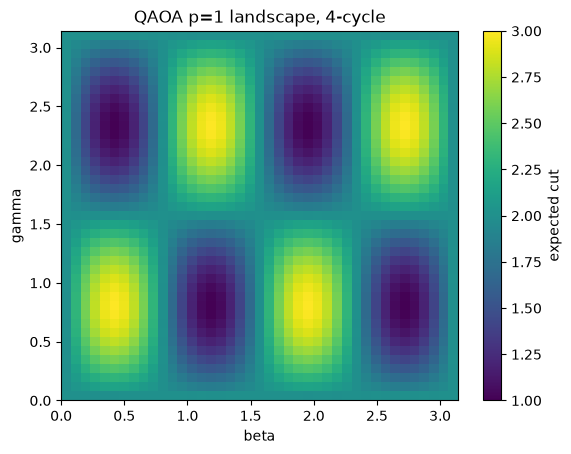

In [6]:
# Plot the energy landscape
import matplotlib.pyplot as plt
plt.imshow(E, origin="lower", extent=[0, np.pi, 0, np.pi], aspect="auto")
plt.xlabel("beta"); plt.ylabel("gamma"); plt.colorbar(label="expected cut")
plt.title("QAOA p=1 landscape, 4-cycle"); plt.show()

In [7]:
# Sample the circuit with the best angles on the Aer simulator and look at the most common cuts
qc = qaoa(gbest, bbest); qc.measure_all()
sim = AerSimulator()
counts = sim.run(transpile(qc, sim), shots=2000).result().get_counts()
top = sorted(counts.items(), key=lambda kv: -kv[1])[:4]
print(top)
assert E.max() > 2.9  # p=1 on a ring reaches 3/4 of the optimum (=3.0), well above random guessing (2.0)

[('1010', 559), ('0101', 520), ('0011', 172), ('1001', 162)]
